(user_guide_optimization_penalty)=

# Constrained Problems with Penalties

📖 {ref}`Particle Swarm Optimization API Reference <api_optimization_PSO>` · {ref}`Differential Evolution API Reference <api_optimization_DE>`

[PSO](pso.ipynb) and [DE](de.ipynb), like the [genetic algorithms](bga.ipynb) and [ACO](aco.ipynb) of the library, only know about one kind of constraint: the box given by `ranges`. Real problems usually come with more, for example

$$
\begin{aligned}
\min_{\mathbf{x}} \quad & f(\mathbf{x}) \\
\text{subject to} \quad & g_i(\mathbf{x}) \le 0, \quad i = 1, \dots, m, \\
& h_j(\mathbf{x}) = 0, \quad j = 1, \dots, p, \\
& \mathbf{x}_{min} \le \mathbf{x} \le \mathbf{x}_{max} .
\end{aligned}
$$

The box constraints go into `ranges`, and the optimizer never leaves the box. The simplest and most common way to handle the rest with a metaheuristic is a **penalty function**: we don't change the optimizer, we change the objective so that violating a constraint costs something.

## Static exterior penalties

The *static exterior penalty* method replaces $f$ with

$$
\phi(\mathbf{x}) = f(\mathbf{x}) + \mu \left[\, \sum_{i=1}^{m} \max\bigl(0,\, g_i(\mathbf{x})\bigr)^{q} + \sum_{j=1}^{p} \bigl|h_j(\mathbf{x})\bigr|^{q} \right],
$$

and minimizes $\phi$ over the box. Some notes on the ingredients:

* **Exterior** means that the penalty is zero inside the feasible region, where $\phi = f$, and grows with the amount of violation outside it. Feasible points keep their objective value, so the optimizers can move freely among them.
* The exponent $q$ is usually 2. A quadratic penalty grows smoothly from zero at the boundary. With $q = 1$, the penalty is *exact* for a large enough $\mu$, meaning the minimizer of $\phi$ is exactly feasible, but it has a kink at the boundary.
* The *penalty weight* $\mu > 0$ sets the price of a violation. For a quadratic penalty, the minimizer of $\phi$ is generally slightly infeasible, and it approaches the true constrained optimum as $\mu \to \infty$. Too small a $\mu$ gives an infeasible "optimum". Too large a $\mu$ makes the landscape steep and narrow around the feasible region, which slows the search down or traps it. We'll see both below.
* Constraints should be **scaled** to comparable magnitudes, e.g. $g(\mathbf{x}) = \sigma(\mathbf{x}) / \sigma_{allow} - 1 \le 0$ instead of $\sigma(\mathbf{x}) - \sigma_{allow} \le 0$, so that a single $\mu$ treats them fairly.
* Equality constraints can be met only approximately. It is often better to eliminate them by solving for one variable, if possible, or to relax them to $|h(\mathbf{x})| \le \varepsilon$.
* For **maximization** (the default of the optimizers), the penalty must make the objective *smaller*, so it is subtracted: $\phi = f - \mu \, [\dots]$.

An alternative is the *death penalty*: return `np.inf` (or `-np.inf` when maximizing) for any infeasible point. It is simple and never returns infeasible solutions. However, it gives the optimizer no hint of *how* infeasible a point is, so it only works if the feasible region is large compared to the box. It also can't handle equality constraints at all.

```{note}
The library doesn't have a helper to build penalized objectives yet, so this page writes them by hand. A helper is planned, see [issue #110](https://github.com/sigma-epsilon/sigmaepsilon.math/issues/110).
```

## A worked example

A classic test problem (Bracken & McCormick, 1968) with one inequality and one equality constraint:

$$
\begin{aligned}
\min_{\mathbf{x}} \quad & f(\mathbf{x}) = (x_0 - 2)^2 + (x_1 - 1)^2 \\
\text{subject to} \quad & g(\mathbf{x}) = x_0^2 / 4 + x_1^2 - 1 \le 0, \\
& h(\mathbf{x}) = x_0 - 2 x_1 + 1 = 0 .
\end{aligned}
$$

Geometrically, we are looking for the point of the line $h = 0$ that lies inside the ellipse $g \le 0$ and is closest to $(2, 1)$. The exact solution is $\mathbf{x}^* \approx (0.8229, 0.9114)$ with $f(\mathbf{x}^*) \approx 1.3935$. Both constraints are active at the optimum.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sigmaepsilon.math.optimize import ParticleSwarmOptimization as PSO
from sigmaepsilon.math.optimize import DifferentialEvolution as DE


def f(x):
    return (x[0] - 2) ** 2 + (x[1] - 1) ** 2


def g(x):  # g(x) <= 0
    return x[0] ** 2 / 4 + x[1] ** 2 - 1


def h(x):  # h(x) == 0
    return x[0] - 2 * x[1] + 1


def penalized(mu, q=2):
    def phi(x):
        violation = max(0.0, g(x)) ** q + abs(h(x)) ** q
        return f(x) + mu * violation

    return phi


x_exact = np.array([0.822876, 0.911438])
ranges = [[-3, 3], [-3, 3]]

`penalized(mu)` returns the penalized objective $\phi$ for a given weight. Let's solve it with both optimizers for increasing values of $\mu$. For every run we print the objective, the constraint values and the distance from the exact solution:

In [2]:
print(f"{'mu':>8} {'optimizer':<5}{'x0':>9}{'x1':>9}{'f(x)':>9}{'g(x)':>10}{'h(x)':>10}{'error':>10}")
results = {}
for mu in [1, 10, 100, 1e4, 1e6]:
    for name, Optimizer in [("PSO", PSO), ("DE", DE)]:
        opt = Optimizer(penalized(mu), ranges, minimize=True, seed=0)
        x = np.array(opt.solve().phenotype)
        results[name, mu] = x
        error = np.linalg.norm(x - x_exact)
        print(f"{mu:>8.0e} {name:<5}{x[0]:>9.4f}{x[1]:>9.4f}{f(x):>9.4f}{g(x):>10.1e}{h(x):>10.1e}{error:>10.1e}")

      mu optimizer       x0       x1     f(x)      g(x)      h(x)     error
   1e+00 PSO     1.3416   0.9778   0.4340   4.1e-01   3.9e-01   5.2e-01
   1e+00 DE      1.3416   0.9778   0.4340   4.1e-01   3.9e-01   5.2e-01
   1e+01 PSO     0.9289   0.9293   1.1522   7.9e-02   7.0e-02   1.1e-01
   1e+01 DE      0.9289   0.9293   1.1522   7.9e-02   7.0e-02   1.1e-01
   1e+02 PSO     0.8351   0.9136   1.3644   9.1e-03   7.9e-03   1.2e-02
   1e+02 DE      0.8351   0.9136   1.3644   9.1e-03   7.9e-03   1.2e-02
   1e+04 PSO     0.8221   0.9108   1.3954  -1.4e-03   4.2e-04   9.7e-04
   1e+04 DE      0.8230   0.9115   1.3932   9.2e-05   8.0e-05   1.3e-04


   1e+06 PSO     0.7913   0.8957   1.4718  -4.1e-02  -8.6e-05   3.5e-02
   1e+06 DE      0.8229   0.9114   1.3935   9.2e-07   8.0e-07   9.0e-07


The table shows the trade-off described above:

* With a **small** $\mu$, the constraints are cheap to violate. The optimizers trade feasibility for a better objective, and the result has a clearly lower $f$ than the true optimum, but $g > 0$ and $h \neq 0$.
* As $\mu$ **grows**, the solution approaches the exact optimum, with violations shrinking roughly in proportion to $1/\mu$.
* With a **very large** $\mu$, the feasible region becomes a narrow, steep-walled valley, and the stagnation-based stopping rule can fire before the optimizer has crept along it. Depending on the optimizer and seed, the result can get *worse* again. Here it can even lie inside the ellipse, away from the optimum on the line.

A value that makes the penalty dominate the objective for meaningful violations, here $\mu \approx 10^4$, usually works well. Always check the constraint values of the result, as we did above. If the run ends close to the boundary of the feasible region, a larger `maxage` helps.

Let's visualize the problem and the solutions for $\mu = 10^4$:

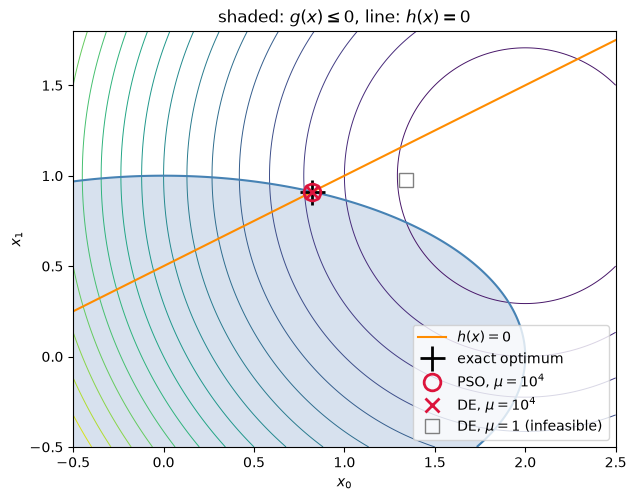

In [3]:
X, Y = np.meshgrid(np.linspace(-0.5, 2.5, 400), np.linspace(-0.5, 1.8, 400))
fig, ax = plt.subplots(figsize=(7, 5.5))
cs = ax.contour(X, Y, f([X, Y]), levels=20, cmap="viridis", linewidths=0.7)
ax.contourf(X, Y, g([X, Y]), levels=[-np.inf, 0], colors=["lightsteelblue"], alpha=0.5)
ax.contour(X, Y, g([X, Y]), levels=[0], colors="steelblue")
t = np.linspace(-0.5, 2.5, 2)
ax.plot(t, (t + 1) / 2, color="darkorange", label="$h(x) = 0$")
ax.plot(*x_exact, "k+", ms=18, mew=2, label="exact optimum")
ax.plot(*results["PSO", 1e4], "o", mfc="none", mec="crimson", ms=12, mew=2, label="PSO, $\\mu=10^4$")
ax.plot(*results["DE", 1e4], "x", color="crimson", ms=10, mew=2, label="DE, $\\mu=10^4$")
ax.plot(*results["DE", 1], "s", mfc="none", mec="gray", ms=10, label="DE, $\\mu=1$ (infeasible)")
ax.set_xlabel("$x_0$")
ax.set_ylabel("$x_1$")
ax.set_title("shaded: $g(x) \\leq 0$, line: $h(x) = 0$")
ax.set_aspect("equal")
ax.legend(loc="lower right");

### Making the penalized objective fast

The penalty function is an ordinary objective, so everything on the [PSO](pso.ipynb) and [DE](de.ipynb) pages applies to it. In particular, it can be vectorized with NumPy, which is much faster than one Python call per candidate. If you want to evaluate in parallel with `n_jobs`, define it at module level (not as a closure, like `penalized` above), because it must be picklable.

In [4]:
def phi_batch(x, mu=1e4):
    fx = (x[:, 0] - 2) ** 2 + (x[:, 1] - 1) ** 2
    gx = x[:, 0] ** 2 / 4 + x[:, 1] ** 2 - 1
    hx = x[:, 0] - 2 * x[:, 1] + 1
    return fx + mu * (np.maximum(0.0, gx) ** 2 + hx**2)


de = DE(phi_batch, ranges, minimize=True, vectorized=True, seed=0)
de.solve().phenotype

[0.8230003559706576, 0.9114603201812893]

### Maximization

When maximizing, the penalty is subtracted. The same problem posed as maximizing $-f$:

In [5]:
def phi_max(x, mu=1e4):
    return -f(x) - mu * (max(0.0, g(x)) ** 2 + h(x) ** 2)


pso = PSO(phi_max, ranges, seed=0)  # maximizes by default
pso.solve().phenotype

[0.8221103687805436, 0.9108469511204522]

## Constraints and multiple solutions

Penalties combine naturally with `n_solutions`. A constraint can turn an unconstrained optimum into a *constrained* one on the boundary of the feasible region, and different boundary optima are just as distinct as interior ones.

Take Himmelblau's function with its four minima, and only allow points inside the disk $x_0^2 + x_1^2 \le 16$. Only one of the four unconstrained minima, $(3, 2)$, lies inside the disk. The other three are cut off, but each of their basins still has a best feasible point, where it meets the circle:

In [6]:
def himmelblau(x):
    return (x[0] ** 2 + x[1] - 11) ** 2 + (x[0] + x[1] ** 2 - 7) ** 2


def himmelblau_in_disk(x, mu=1e3):
    return himmelblau(x) + mu * max(0.0, x[0] ** 2 + x[1] ** 2 - 16) ** 2


box = [[-5, 5], [-5, 5]]
solutions = {}
for name, Optimizer in [("PSO", PSO), ("DE", DE)]:
    opt = Optimizer(himmelblau_in_disk, box, nPop=60, minimize=True, n_solutions=4, seed=0)
    opt.solve()
    solutions[name] = opt.solutions
    print(name)
    for s in opt.solutions:
        x = np.array(s.phenotype)
        print(f"   x = {np.round(x, 4)},  f(x) = {himmelblau(x):8.4f},  |x| = {np.linalg.norm(x):.4f}")

PSO
   x = [3. 2.],  f(x) =   0.0000,  |x| = 3.6056
   x = [ 3.5655 -1.8131],  f(x) =   0.0317,  |x| = 4.0000
   x = [-2.6517  2.9949],  f(x) =   1.4135,  |x| = 4.0001
   x = [-3.1223 -2.5009],  f(x) =  29.0405,  |x| = 4.0004
DE
   x = [3. 2.],  f(x) =   0.0000,  |x| = 3.6056
   x = [ 3.5656 -1.8129],  f(x) =   0.0317,  |x| = 4.0000
   x = [-2.6517  2.9949],  f(x) =   1.4135,  |x| = 4.0001
   x = [-3.1232 -2.4998],  f(x) =  29.0391,  |x| = 4.0004


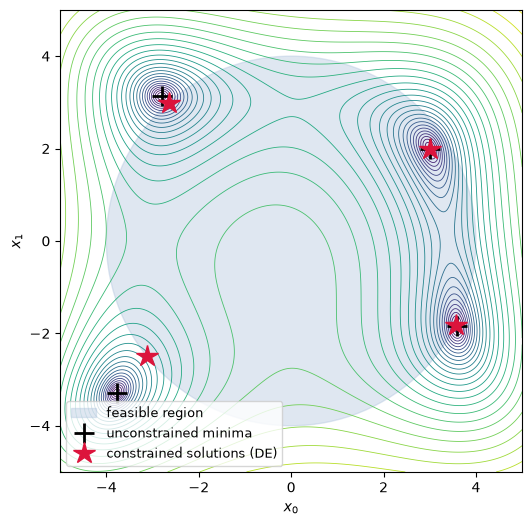

In [7]:
X, Y = np.meshgrid(np.linspace(-5, 5, 400), np.linspace(-5, 5, 400))
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.contour(X, Y, np.log1p(himmelblau([X, Y])), levels=30, cmap="viridis", linewidths=0.6)
ax.add_patch(plt.Circle((0, 0), 4, color="lightsteelblue", alpha=0.4, label="feasible region"))
ax.plot(*np.array([[3.0, 2.0], [-2.805, 3.131], [-3.779, -3.283], [3.584, -1.848]]).T,
        "k+", ms=14, mew=2, label="unconstrained minima")
for s in solutions["DE"]:
    ax.plot(*s.phenotype, "*", color="crimson", ms=16)
ax.plot([], [], "*", color="crimson", ms=16, label="constrained solutions (DE)")
ax.set_aspect("equal")
ax.set_xlabel("$x_0$")
ax.set_ylabel("$x_1$")
ax.legend(loc="lower left", fontsize=9);

Both optimizers return the interior minimum and the three constrained minima on the circle, each exactly once and ranked by objective value. The hill-valley test that identifies distinct basins sees the *penalized* objective, so it separates feasible optima just as it separates unconstrained ones.

## Summary

* Put simple bounds into `ranges` and everything else into a penalty.
* Use a static quadratic exterior penalty, $\phi = f \pm \mu \sum \text{violation}^2$: add it when minimizing, subtract it when maximizing.
* Scale the constraints, and choose $\mu$ large enough to make violations clearly unprofitable but not so large that the landscape becomes a narrow canyon. Try a few values if in doubt.
* Always check the constraint values of the returned solutions.
* Penalties work the same way for PSO, DE, the genetic algorithms and ACO, with `vectorized`/`n_jobs` evaluation and with `n_solutions`.